In [1]:
# Question 1: Seaborn - Fitness Club Analysis
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

members = pd.DataFrame({
    "member_id": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "plan": ["Basic", "Standard", "Premium", "Basic", "Standard", "Premium",
             "Basic", "Standard", "Premium", "Basic", "Standard", "Premium"],
    "branch": ["North", "North", "North", "South", "South", "South",
               "North", "North", "South", "South", "North", "South"],
    "training_hours": [2, 3, 5, 3, 4, 6, 2, 4, 7, 3, 5, 8],
    "sessions_attended": [8, 10, 14, 9, 12, 16, 7, 11, 18, 10, 13, 20],
    "fitness_score": [50, 58, 70, 56, 64, 78, 52, 66, 85, 60, 72, 92]
})
members

,member_id,plan,branch,training_hours,sessions_attended,fitness_score
0,1,Basic,North,2,8,50
1,2,Standard,North,3,10,58
2,3,Premium,North,5,14,70
3,4,Basic,South,3,9,56
4,5,Standard,South,4,12,64
5,6,Premium,South,6,16,78
6,7,Basic,North,2,7,52
7,8,Standard,North,4,11,66
8,9,Premium,South,7,18,85
9,10,Basic,South,3,10,60


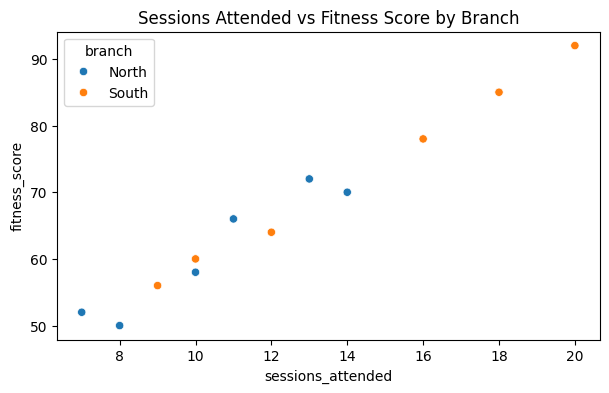

In [2]:
# Part 1: Scatter plot with hue
plt.figure(figsize=(7, 4))
sns.scatterplot(data=members, x="sessions_attended", y="fitness_score", hue="branch")
plt.title("Sessions Attended vs Fitness Score by Branch")
plt.show()

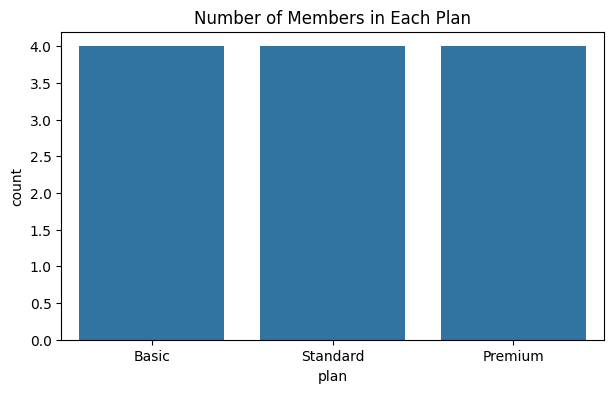

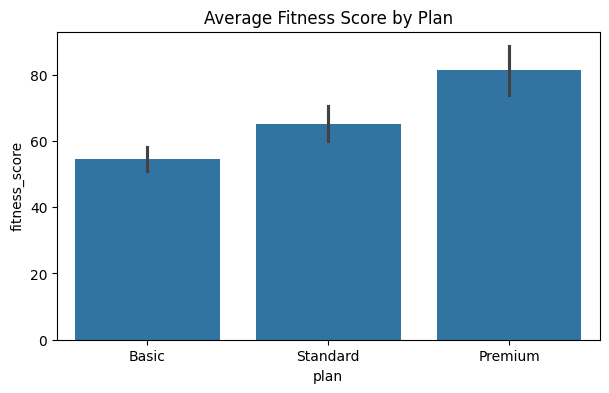

In [3]:
# Part 2: Count plot
plt.figure(figsize=(7, 4))
sns.countplot(data=members, x="plan")
plt.title("Number of Members in Each Plan")
plt.show()

# Part 2: Bar plot (average fitness score)
plt.figure(figsize=(7, 4))
sns.barplot(data=members, x="plan", y="fitness_score")
plt.title("Average Fitness Score by Plan")
plt.show()

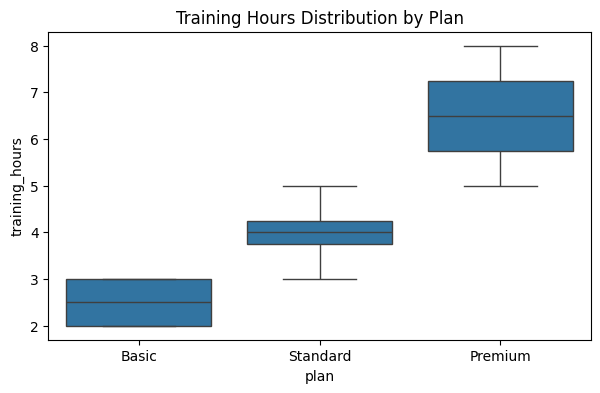

In [4]:
# Part 3: Box plot
plt.figure(figsize=(7, 4))
sns.boxplot(data=members, x="plan", y="training_hours")
plt.title("Training Hours Distribution by Plan")
plt.show()

                   training_hours  sessions_attended  fitness_score
training_hours           1.000000           0.993279       0.996061
sessions_attended        0.993279           1.000000       0.987810
fitness_score            0.996061           0.987810       1.000000


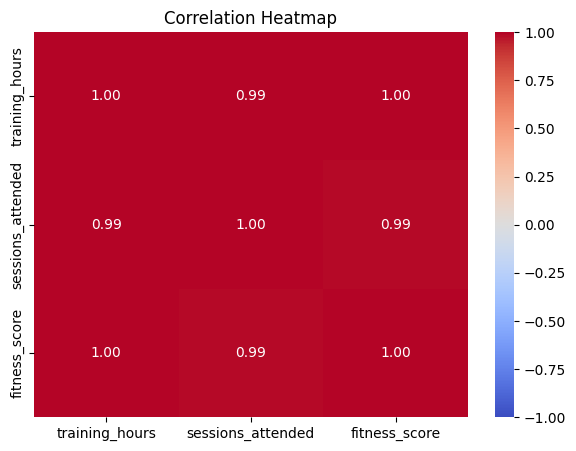

In [5]:
# Part 4: Correlation heatmap
corr = members[["training_hours", "sessions_attended", "fitness_score"]].corr()
print(corr)

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

Question 2:

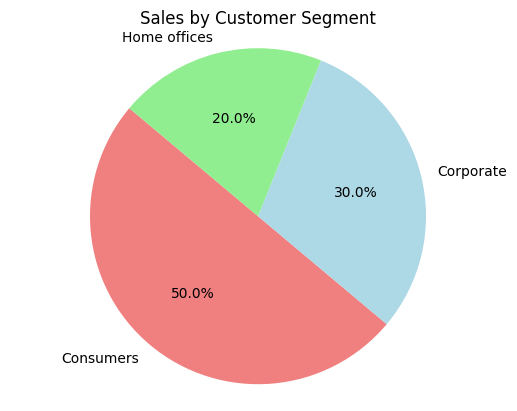

In [6]:
# Question 2: Pie chart of sales by customer segment
import matplotlib.pyplot as plt

labels = ['Consumers', 'Corporate', 'Home offices']
sizes = [50, 30, 20]
colors = ['lightcoral', 'lightblue', 'lightgreen']

plt.pie(sizes, labels=labels, colors=colors, autopct="%1.1f%%", startangle=140)
plt.axis("equal")
plt.title("Sales by Customer Segment")
plt.show()

Question 3:

In [7]:
# Question 3: Plotly Express - Gapminder 2007
import plotly.express as px

gap = px.data.gapminder().query("year == 2007")
gap.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
11,Afghanistan,Asia,2007,43.828,31889923,974.580338,AFG,4
23,Albania,Europe,2007,76.423,3600523,5937.029526,ALB,8
35,Algeria,Africa,2007,72.301,33333216,6223.367465,DZA,12
47,Angola,Africa,2007,42.731,12420476,4797.231267,AGO,24
59,Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32


In [8]:
# Part 1: Bubble chart
fig = px.scatter(gap, x="gdpPercap", y="lifeExp",
                 color="continent", size="pop", size_max=60,
                 hover_name="country", log_x=True,
                 labels={"gdpPercap": "GDP per capita (US$, log scale)",
                         "lifeExp": "Life expectancy (years)"},
                 title="Richer countries tend to live longer, but the gain flattens out")
fig.show()

In [9]:
# Part 2: Horizontal bar chart - top 10 life expectancy
top10 = gap.sort_values("lifeExp", ascending=False).head(10)
top10 = top10.sort_values("lifeExp")   # so the highest bar appears at the top

fig = px.bar(top10, x="lifeExp", y="country", orientation="h",
             text="lifeExp",
             title="Top 10 countries by life expectancy, 2007")
fig.show()

In [10]:
# Part 3: Choropleth map
fig = px.choropleth(gap, locations="iso_alpha", color="lifeExp",
                    hover_name="country",
                    color_continuous_scale="Viridis",
                    title="Life expectancy across the world, 2007")
fig.show()

### Part 4: Insight
Africa looks the most different from the rest. Most African countries are clustered in the bottom-left of the chart, with low GDP per capita and life expectancy mostly between about 40 and 60 years, while most countries on the other continents are above 70 years.

Question 4:



In [11]:
# Question 4: Airline passengers dataset (1949-1960)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

flights = sns.load_dataset("flights")
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


year
1949    1520
1950    1676
1951    2042
1952    2364
1953    2700
1954    2867
1955    3408
1956    3939
1957    4421
1958    4572
1959    5140
1960    5714
Name: passengers, dtype: int64


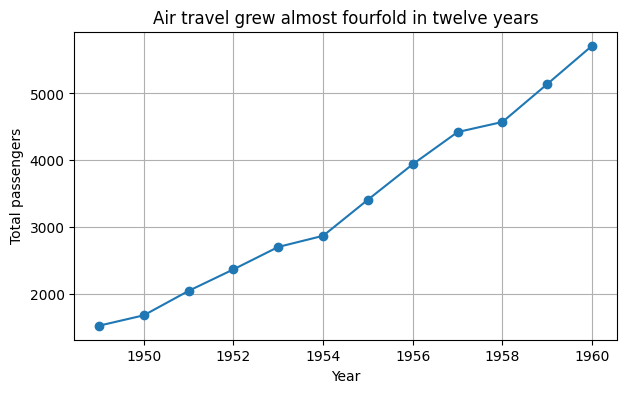

In [12]:
# Part 1: Matplotlib - yearly trend
yearly = flights.groupby("year")["passengers"].sum()
print(yearly)

plt.figure(figsize=(7, 4))
plt.plot(yearly.index, yearly.values, marker="o")
plt.xlabel("Year")
plt.ylabel("Total passengers")
plt.title("Air travel grew almost fourfold in twelve years")
plt.grid(True)
plt.show()

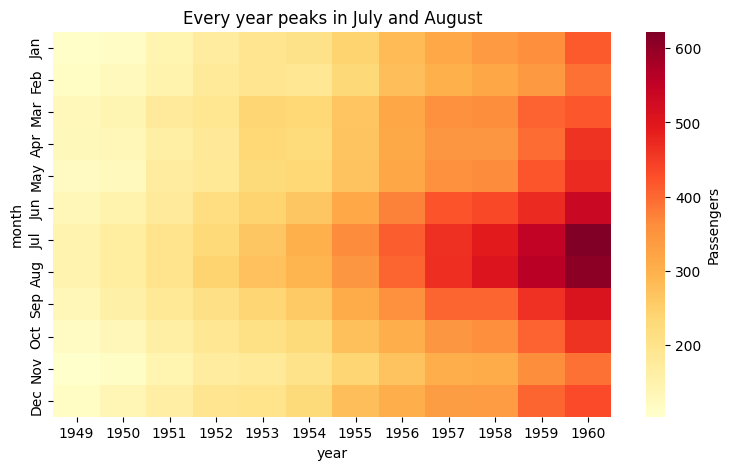

In [13]:
# Part 2: Seaborn - seasonal heatmap
table = flights.pivot(index="month", columns="year", values="passengers")

plt.figure(figsize=(9, 5))
sns.heatmap(table, cmap="YlOrRd", cbar_kws={"label": "Passengers"})
plt.title("Every year peaks in July and August")
plt.show()

In [14]:
# Part 3: Plotly - interactive line chart
flights["date"] = pd.date_range(start="1949-01-01", periods=144, freq="MS")

fig = px.line(flights, x="date", y="passengers",
              hover_data=["passengers"],
              title="Passengers over time: hover to explore any month")
fig.update_xaxes(rangeslider_visible=True)
fig.show()

### Part 4: Comparison

**a)** The Matplotlib line chart showed the trend best. Summing the passengers per year removes the monthly ups and downs, so the single rising line makes the steady, almost fourfold growth easy to see. The Seaborn heatmap showed the seasonal pattern best. Each row is a month, so the July and August rows are clearly the darkest in every year. The colors also get darker from left to right, which shows the growth at the same time.

**b)** For a printed report I would choose Matplotlib, because it gives full control over a clean, static figure. For quick data exploration I would choose Seaborn, because it makes useful statistical plots like heatmaps and box plots directly from a DataFrame in one line. For a website I would choose Plotly, because its charts are interactive, with hover, zoom and a range slider, and can be embedded as HTML.